# PCD Assignment 03 — Segmentasi Citra & Pengolahan Morfologi

**Tujuan:** membuat satu metode segmentasi dan beberapa operasi morfologi, lalu membandingkan hasil segmentasi **sebelum** dan **sesudah** diberi pengolahan morfologi pada **empat citra masukan** dengan **satu kode yang sama** (hanya parameternya yang disesuaikan per citra).

| Bagian | Yang dibuat |
|---|---|
| Segmentasi | **Thresholding otomatis Otsu** (histogram → varians antar-kelas → ambang batas terbaik) |
| Morfologi | **Erosi, Dilasi, Opening, Closing, Ekstraksi batas (boundary), Pengisian lubang (hole filling)** |
| Analisis | **Pelabelan komponen terhubung** (BFS), penyaringan area, dan metrik perbandingan |
| Citra masukan | 1) Daun berbintik putih · 2) Butir beras di latar hitam · 3) Biji kopi di latar putih · 4) citra sintetis dengan noise |

## 1. Persiapan

## 2. Fungsi pembaca citra

* `rgb_to_gray` — konversi manual ke grayscale: $Y = 0.299R + 0.587G + 0.114B$
* `shrink` — memperkecil citra besar dengan merata-ratakan blok piksel, supaya program tidak lambat
* `make_synthetic` — membuat citra contoh yang berderau (noise Gaussian + salt-and-pepper) **beserta ground truth**-nya, sehingga hasil segmentasi bisa dinilai dengan angka

In [20]:
import os
import matplotlib.pyplot as plt
import numpy as np


def cari_file(path):
    """Cari file gambar; jika ekstensi berbeda, coba ekstensi lain."""
    if os.path.exists(path):
        return path
    stem = os.path.splitext(path)[0]
    for ext in (".png", ".jpg", ".jpeg", ".PNG", ".JPG", ".JPEG"):
        alt_path = stem + ext
        if os.path.exists(alt_path):
            return alt_path
    raise FileNotFoundError(path)


def rgb_to_gray(img):
    """Konversi manual ke grayscale: Y = 0.299 R + 0.587 G + 0.114 B."""
    if img.ndim == 2:
        return img.astype(np.float64)
    return 0.299 * img[..., 0] + 0.587 * img[..., 1] + 0.114 * img[..., 2]


def shrink(img, max_size):
    """Kecilkan citra dengan merata-ratakan blok piksel."""
    f = int(np.ceil(max(img.shape) / max_size))
    if f <= 1:
        return img
    H = (img.shape[0] // f) * f
    W = (img.shape[1] // f) * f
    blocks = img[:H, :W].astype(np.float64).reshape(H // f, f, W // f, f)
    return blocks.mean(axis=(1, 3))


def muat_gambar(path, max_size=400):
    raw = plt.imread(cari_file(path))
    if raw.dtype != np.uint8:  # PNG dibaca sebagai float 0..1
        raw = raw * 255
    if raw.ndim == 3:
        raw = raw[..., :3]  # buang channel alpha jika ada
    gray = shrink(rgb_to_gray(raw), max_size)
    return np.clip(gray, 0, 255).astype(np.uint8)


def make_synthetic(size=256):
    """Objek terang di atas latar yang lebih gelap dengan pencahayaan tidak merata,

    ditambah noise Gaussian dan salt-and-pepper.
    """
    yy, xx = np.mgrid[0:size, 0:size]
    gt = np.zeros((size, size), dtype=np.uint8)

    # Lingkaran
    for cy, cx, r in [(60, 60, 30), (70, 190, 25), (180, 70, 28), (190, 190, 22)]:
        gt[(yy - cy) ** 2 + (xx - cx) ** 2 <= r**2] = 1

    # Persegi panjang
    gt[110:150, 110:150] = 1
    gt[20:45, 120:170] = 1
    gt[215:240, 110:160] = 1

    # Gradasi cahaya latar belakang
    background = 55 + 35 * (xx / size)

    # Gabungkan latar dan objek
    img = np.where(gt == 1, 175, background)

    # Tambah noise Gaussian & Salt-and-Pepper
    img = img + np.random.normal(0, 24, img.shape)
    r = np.random.rand(size, size)
    img[r < 0.025] = 255  # salt
    img[r > 0.975] = 0  # pepper

    return np.clip(img, 0, 255).astype(np.uint8), gt

## 3. Segmentasi — Thresholding Otsu (dibuat dari nol)

Metode Otsu mencari ambang batas *t* yang membuat **varians antar-kelas** sebesar mungkin:

$$\sigma_B^2(t) = \omega_0(t)\,\omega_1(t)\,[\mu_0(t)-\mu_1(t)]^2$$

dengan $\omega_{0,1}$ adalah probabilitas masing-masing kelas, dan $\mu_{0,1}$ adalah rata-rata intensitas kelas di kiri dan kanan *t*.  
Singkatnya: Otsu mencari titik pemisah yang paling "rapi" antara kelompok piksel gelap dan kelompok piksel terang.

In [21]:
def compute_histogram(img, bins=256):
    hist = np.zeros(bins, dtype=np.int64)
    for v in img.ravel():          # dihitung manual, tanpa np.histogram
        hist[v] += 1
    return hist

def otsu_threshold(img):
    hist = compute_histogram(img)
    prob = hist / img.size
    levels = np.arange(256)

    best_t, best_var = 0, -1.0
    w0, sum0 = 0.0, 0.0
    mu_total = np.sum(levels * prob)

    for t in range(256):
        w0 += prob[t]
        sum0 += t * prob[t]
        w1 = 1.0 - w0
        if w0 == 0 or w1 == 0:
            continue
        mu0 = sum0 / w0
        mu1 = (mu_total - sum0) / w1
        var_between = w0 * w1 * (mu0 - mu1) ** 2
        if var_between > best_var:
            best_var, best_t = var_between, t
    return best_t, hist

def threshold(img, t):
    return (img > t).astype(np.uint8)

## 4. Operasi morfologi (dibuat dari nol)

Untuk citra biner *A* dan structuring element (SE) *B*:

* **Erosi**  $A \ominus B$ — piksel tetap bernilai 1 hanya jika SE yang diletakkan di situ **muat sepenuhnya** di dalam objek (AND dari salinan yang digeser). Efeknya objek mengecil.
* **Dilasi** $A \oplus B$ — piksel menjadi 1 jika SE menyentuh **salah satu** piksel objek (OR dari salinan yang digeser). Efeknya objek membesar.
* **Opening**  $A \circ B = (A \ominus B) \oplus B$ — menghapus bintik putih kecil yang terpisah, bentuk objek besar tetap terjaga.
* **Closing**  $A \bullet B = (A \oplus B) \ominus B$ — menutup lubang dan celah kecil.
* **Boundary** $\beta(A) = A - (A \ominus B)$ — mengambil garis tepi objek.
* **Hole filling** — mengisi semua lubang yang terkurung di dalam objek (dijelaskan di bagian 5).

In [22]:
# ---------- Structuring element ----------
def se_square(k):
    return np.ones((k, k), dtype=np.uint8)

def se_cross(k):
    se = np.zeros((k, k), dtype=np.uint8)
    c = k // 2
    se[c, :] = 1; se[:, c] = 1
    return se

def se_disk(r):
    yy, xx = np.mgrid[-r:r+1, -r:r+1]
    return ((yy**2 + xx**2) <= r**2).astype(np.uint8)

# ---------- Operasi inti ----------
def erosion(img, se):
    H, W = img.shape
    kh, kw = se.shape
    cy, cx = kh // 2, kw // 2
    padded = np.pad(img, ((cy, kh-cy-1), (cx, kw-cx-1)), constant_values=1)   # padding 1 -> tepi citra tidak ikut terkikis
    out = np.ones((H, W), dtype=np.uint8)
    for i in range(kh):
        for j in range(kw):
            if se[i, j]:
                out &= padded[i:i+H, j:j+W]        # AND dari salinan yang digeser
    return out

def dilation(img, se):
    H, W = img.shape
    se_r = se[::-1, ::-1]                           # pencerminan SE
    kh, kw = se_r.shape
    cy, cx = kh // 2, kw // 2
    padded = np.pad(img, ((cy, kh-cy-1), (cx, kw-cx-1)), constant_values=0)
    out = np.zeros((H, W), dtype=np.uint8)
    for i in range(kh):
        for j in range(kw):
            if se_r[i, j]:
                out |= padded[i:i+H, j:j+W]        # OR dari salinan yang digeser
    return out

def opening(img, se):  return dilation(erosion(img, se), se)
def closing(img, se):  return erosion(dilation(img, se), se)
def boundary(img, se): return img & (1 - erosion(img, se))

# ---------- Uji cepat pada array kecil ----------
test = np.zeros((7, 7), dtype=np.uint8); test[2:5, 2:5] = 1; test[0, 6] = 1
print("Asli:\n", test)
print("Erosi (3x3):\n", erosion(test, se_square(3)))
print("Dilasi (3x3):\n", dilation(test, se_square(3)))

Asli:
 [[0 0 0 0 0 0 1]
 [0 0 0 0 0 0 0]
 [0 0 1 1 1 0 0]
 [0 0 1 1 1 0 0]
 [0 0 1 1 1 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]]
Erosi (3x3):
 [[0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 1 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]]
Dilasi (3x3):
 [[0 0 0 0 0 1 1]
 [0 1 1 1 1 1 1]
 [0 1 1 1 1 1 0]
 [0 1 1 1 1 1 0]
 [0 1 1 1 1 1 0]
 [0 1 1 1 1 1 0]
 [0 0 0 0 0 0 0]]


## 5. Pelabelan komponen terhubung & pengisian lubang (dibuat dari nol)

* **Pelabelan komponen terhubung** dipakai untuk **menghitung jumlah wilayah** dan **membuang wilayah kecil**. Caranya dengan pencarian BFS (*breadth-first search*) memakai 8-ketetanggaan, sehingga tiap gumpalan piksel mendapat label sendiri.
* **Pengisian lubang (hole filling)**: latar ditelusuri dari tepi citra. Piksel latar yang tidak terjangkau berarti terkurung di dalam objek, sehingga dianggap lubang dan diisi.

In [23]:
def label_components(binary):
    H, W = binary.shape
    labels = np.zeros((H, W), dtype=np.int32)
    areas = {}
    current = 0
    neighbours = [(-1,-1),(-1,0),(-1,1),(0,-1),(0,1),(1,-1),(1,0),(1,1)]
    for y in range(H):
        for x in range(W):
            if binary[y, x] and labels[y, x] == 0:
                current += 1
                labels[y, x] = current
                q = deque([(y, x)]); area = 0
                while q:
                    cy, cx = q.popleft(); area += 1
                    for dy, dx in neighbours:
                        ny, nx = cy+dy, cx+dx
                        if 0 <= ny < H and 0 <= nx < W and binary[ny, nx] and labels[ny, nx] == 0:
                            labels[ny, nx] = current
                            q.append((ny, nx))
                areas[current] = area
    return labels, areas

def remove_small_objects(binary, min_area):
    labels, areas = label_components(binary)
    out = np.zeros_like(binary)
    for lab, a in areas.items():
        if a >= min_area:
            out[labels == lab] = 1
    return out

def count_objects(binary, min_area=1):
    _, areas = label_components(binary)
    return sum(1 for a in areas.values() if a >= min_area)

def fill_holes(binary):
    """Isi lubang: telusuri latar dari tepi citra (4-ketetanggaan).
    Piksel latar yang tidak terjangkau = terkurung di dalam objek = lubang."""
    H, W = binary.shape
    reached = np.zeros((H, W), dtype=bool)
    q = deque()
    for y in range(H):
        for x in (0, W - 1):
            if not binary[y, x] and not reached[y, x]:
                reached[y, x] = True; q.append((y, x))
    for x in range(W):
        for y in (0, H - 1):
            if not binary[y, x] and not reached[y, x]:
                reached[y, x] = True; q.append((y, x))
    while q:
        cy, cx = q.popleft()
        for dy, dx in ((-1,0),(1,0),(0,-1),(0,1)):
            ny, nx = cy+dy, cx+dx
            if 0 <= ny < H and 0 <= nx < W and not binary[ny, nx] and not reached[ny, nx]:
                reached[ny, nx] = True; q.append((ny, nx))
    return (~reached).astype(np.uint8)

def count_holes(binary):
    holes = fill_holes(binary) & (1 - binary)
    return count_objects(holes)

## 6. Fungsi pipeline: segmentasi tanpa vs. dengan morfologi

Satu fungsi `proses_gambar` menjalankan seluruh alur untuk satu citra:

**Otsu → (hasil TANPA morfologi) → Opening → Closing → Isi lubang → Buang wilayah kecil → (hasil DENGAN morfologi)**

Parameter yang bisa diatur per citra:

| Parameter | Fungsi |
|---|---|
| `objek_terang` | `True` kalau objek lebih terang dari latar, `False` kalau lebih gelap |
| `se_radius` | Radius structuring element untuk opening/closing |
| `isi_lubang` | `True` untuk mengisi semua lubang di dalam objek |
| `min_area` | Wilayah dengan luas (piksel) di bawah angka ini dibuang |
| `max_size` | Sisi terpanjang maksimum citra (piksel); yang lebih besar dikecilkan |

In [24]:
def metrics(pred, gt):
    pred, gt = pred.astype(bool), gt.astype(bool)
    tp = np.sum(pred & gt); fp = np.sum(pred & ~gt); fn = np.sum(~pred & gt); tn = np.sum(~pred & ~gt)
    return dict(IoU=tp/(tp+fp+fn), Dice=2*tp/(2*tp+fp+fn), Precision=tp/(tp+fp),
                Recall=tp/(tp+fn), Accuracy=(tp+tn)/(tp+tn+fp+fn))

def overlay_edges(gray, mask):
    """Garis tepi merah dari area hasil segmentasi di atas citra grayscale."""
    edge = boundary(mask, se_square(3)).astype(bool)
    rgb = np.stack([gray]*3, axis=-1).astype(np.uint8)
    rgb[edge] = [255, 0, 0]
    return rgb

def proses_gambar(nama, path=None, objek_terang=True, se_radius=1, isi_lubang=False,
                  min_area=60, max_size=400, tampil_operasi_dasar=False):
    print("="*70); print(f"  {nama}"); print("="*70)

    # ---- 1. muat citra ----
    if path is None:
        gray_view, gt = make_synthetic()
    else:
        gray_view, gt = muat_gambar(path, max_size), None
    gray = gray_view if objek_terang else 255 - gray_view     # balik supaya objek menjadi terang
    print(f"Ukuran citra: {gray.shape} | ground truth: {'ada' if gt is not None else 'tidak ada'}")

    # ---- 2. segmentasi Otsu (TANPA morfologi) ----
    t, hist = otsu_threshold(gray)
    seg_raw = threshold(gray, t)
    print("Ambang batas Otsu =", t)
    tepi = np.concatenate([seg_raw[0, :], seg_raw[-1, :], seg_raw[:, 0], seg_raw[:, -1]])
    if tepi.mean() > 0.5:
        print("PERINGATAN: sebagian besar tepi citra terdeteksi sebagai OBJEK. Biasanya ini berarti "
              "`objek_terang` terbalik (yang tersegmentasi justru latarnya). Coba ganti nilainya.")

    fig, ax = plt.subplots(1, 3, figsize=(13, 3.9))
    ax[0].imshow(gray_view, cmap='gray', vmin=0, vmax=255); ax[0].set_title("Citra masukan (grayscale)"); ax[0].axis('off')
    ax[1].bar(range(256), hist, width=1.0, color='gray'); ax[1].set_yscale('log')
    ax[1].axvline(t, color='r', ls='--', label=f"Otsu t = {t}"); ax[1].set_title("Histogram (sumbu y log)"); ax[1].legend()
    ax[2].imshow(seg_raw, cmap='gray'); ax[2].set_title("Segmentasi TANPA morfologi"); ax[2].axis('off')
    plt.tight_layout(); plt.show()

    # ---- 3. efek tiap operasi dasar ----
    if tampil_operasi_dasar:
        s2 = se_disk(2)
        ops = {"Segmentasi mentah": seg_raw, "Erosi": erosion(seg_raw, s2), "Dilasi": dilation(seg_raw, s2),
               "Opening": opening(seg_raw, s2), "Closing": closing(seg_raw, s2),
               "Boundary (dari hasil opening)": boundary(opening(seg_raw, s2), se_square(3))}
        fig, axes = plt.subplots(2, 3, figsize=(11, 7.4))
        for a, (nm, im) in zip(axes.ravel(), ops.items()):
            a.imshow(im, cmap='gray'); a.set_title(nm if nm.startswith(("Segmentasi", "Boundary")) else nm + "  (SE disk r=2)"); a.axis('off')
        plt.tight_layout(); plt.show()

    # ---- 4. pipeline morfologi ----
    se = se_disk(se_radius)
    step1 = opening(seg_raw, se)                         # hapus noise putih yang terpisah
    step2 = closing(step1, se)                           # tutup lubang kecil
    step3 = fill_holes(step2) if isi_lubang else step2   # isi sisa lubang (opsional)
    seg_morph = remove_small_objects(step3, min_area)    # buang wilayah kecil

    panels = [("Otsu (mentah)", seg_raw), (f"+ Opening (r={se_radius})", step1), ("+ Closing", step2)]
    if isi_lubang:
        panels.append(("+ Isi lubang", step3))
    panels.append(("+ Buang objek kecil", seg_morph))
    fig, axes = plt.subplots(1, len(panels), figsize=(3.4*len(panels), 3.4))
    for a, (ttl, im) in zip(axes, panels):
        a.imshow(im, cmap='gray'); a.set_title(ttl); a.axis('off')
    plt.tight_layout(); plt.show()

    # ---- 5. perbandingan tanpa vs. dengan morfologi ----
    n_raw, n_morph = count_objects(seg_raw), count_objects(seg_morph)
    h_raw, h_morph = count_holes(seg_raw), count_holes(seg_morph)
    luas_raw, luas_morph = seg_raw.mean()*100, seg_morph.mean()*100

    cols = 4 if gt is not None else 3
    fig, axes = plt.subplots(1, cols, figsize=(4.2*cols, 4.6))
    axes[0].imshow(gray_view, cmap='gray'); axes[0].set_title("Citra masukan")
    axes[1].imshow(overlay_edges(gray_view, seg_raw)); axes[1].set_title(f"TANPA morfologi\n{n_raw} wilayah, {h_raw} lubang")
    axes[2].imshow(overlay_edges(gray_view, seg_morph)); axes[2].set_title(f"DENGAN morfologi\n{n_morph} wilayah, {h_morph} lubang")
    if gt is not None:
        axes[3].imshow(gt, cmap='gray'); axes[3].set_title("Ground truth (kunci jawaban)")
    for a in axes: a.axis('off')
    plt.tight_layout(); plt.show()

    hasil = dict(nama=nama, t=t, n_raw=n_raw, n_morph=n_morph, h_raw=h_raw, h_morph=h_morph,
                 luas_raw=luas_raw, luas_morph=luas_morph)

    print(f"{'':<22}{'Tanpa morfologi':>17}{'Dengan morfologi':>18}")
    print("-"*57)
    print(f"{'Jumlah wilayah':<22}{n_raw:>17d}{n_morph:>18d}")
    print(f"{'Jumlah lubang':<22}{h_raw:>17d}{h_morph:>18d}")
    print(f"{'Luas objek (% citra)':<22}{luas_raw:>17.1f}{luas_morph:>18.1f}")

    # ---- 6. metrik kuantitatif (kalau ada ground truth) ----
    if gt is not None:
        m_raw, m_morph = metrics(seg_raw, gt), metrics(seg_morph, gt)
        hasil.update(iou_raw=m_raw["IoU"], iou_morph=m_morph["IoU"])
        print(f"\nJumlah objek sebenarnya (ground truth): {count_objects(gt)}\n")
        print(f"{'Metrik':<12}{'Tanpa morfologi':>17}{'Dengan morfologi':>18}{'Selisih':>10}")
        print("-"*57)
        for k in m_raw:
            print(f"{k:<12}{m_raw[k]:>17.4f}{m_morph[k]:>18.4f}{m_morph[k]-m_raw[k]:>+10.4f}")

        keys = list(m_raw); x = np.arange(len(keys)); w = 0.38
        fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
        ax[0].bar(x - w/2, [m_raw[k] for k in keys],   w, label="Tanpa morfologi", color="#d9534f")
        ax[0].bar(x + w/2, [m_morph[k] for k in keys], w, label="Dengan morfologi", color="#5cb85c")
        ax[0].set_xticks(x); ax[0].set_xticklabels(keys); ax[0].set_ylim(0, 1.05)
        ax[0].legend(loc="lower right"); ax[0].set_title("Kualitas segmentasi")

        # percobaan ukuran SE
        radii = [0, 1, 2, 3, 4, 5, 6]; scores = []
        for r in radii:
            if r == 0:
                res = seg_raw
            else:
                s = se_disk(r)
                res = remove_small_objects(closing(opening(seg_raw, s), s), min_area)
            scores.append(metrics(res, gt)["IoU"])
        ax[1].plot(radii, scores, 'o-'); ax[1].grid(alpha=.3)
        ax[1].set_xlabel("Radius SE disk (0 = tanpa morfologi)"); ax[1].set_ylabel("IoU")
        ax[1].set_title("Pengaruh ukuran structuring element")
        plt.tight_layout(); plt.show()
        print("Radius SE terbaik:", radii[int(np.argmax(scores))], "-> IoU =", round(max(scores), 4))

        # peta kesalahan
        fig, ax = plt.subplots(1, 2, figsize=(8, 4))
        for a, seg, ttl in zip(ax, [seg_raw, seg_morph], ["Kesalahan TANPA morfologi", "Kesalahan DENGAN morfologi"]):
            err = np.zeros(seg.shape + (3,), dtype=np.uint8) + 255
            err[(seg == 1) & (gt == 1)] = [120, 200, 120]   # benar (hijau)
            err[(seg == 1) & (gt == 0)] = [230, 60, 60]     # false positive (merah)
            err[(seg == 0) & (gt == 1)] = [60, 90, 230]     # false negative (biru)
            a.imshow(err); a.set_title(ttl); a.axis('off')
        plt.suptitle("hijau = benar, merah = salah deteksi (false positive), biru = terlewat (false negative)", y=0.02, fontsize=9)
        plt.tight_layout(); plt.show()

    return hasil

## 7. Citra 1 — Daun berbintik putih

**Tantangan:** bercak putih di daun kecerahannya mirip latar, sehingga Otsu menganggapnya sebagai latar → daun jadi **berlubang-lubang**.  
**Strategi:** daun lebih gelap dari latar (`objek_terang=False`), lalu pakai closing dan **pengisian lubang**.

  Citra 1 — Daun berbintik putih
Ukuran citra: (370, 321) | ground truth: tidak ada
Ambang batas Otsu = 93


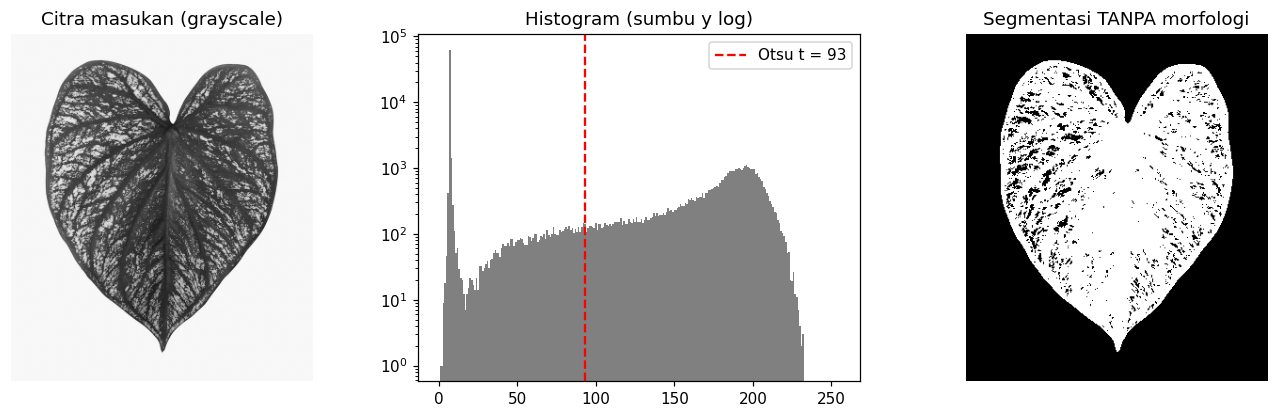

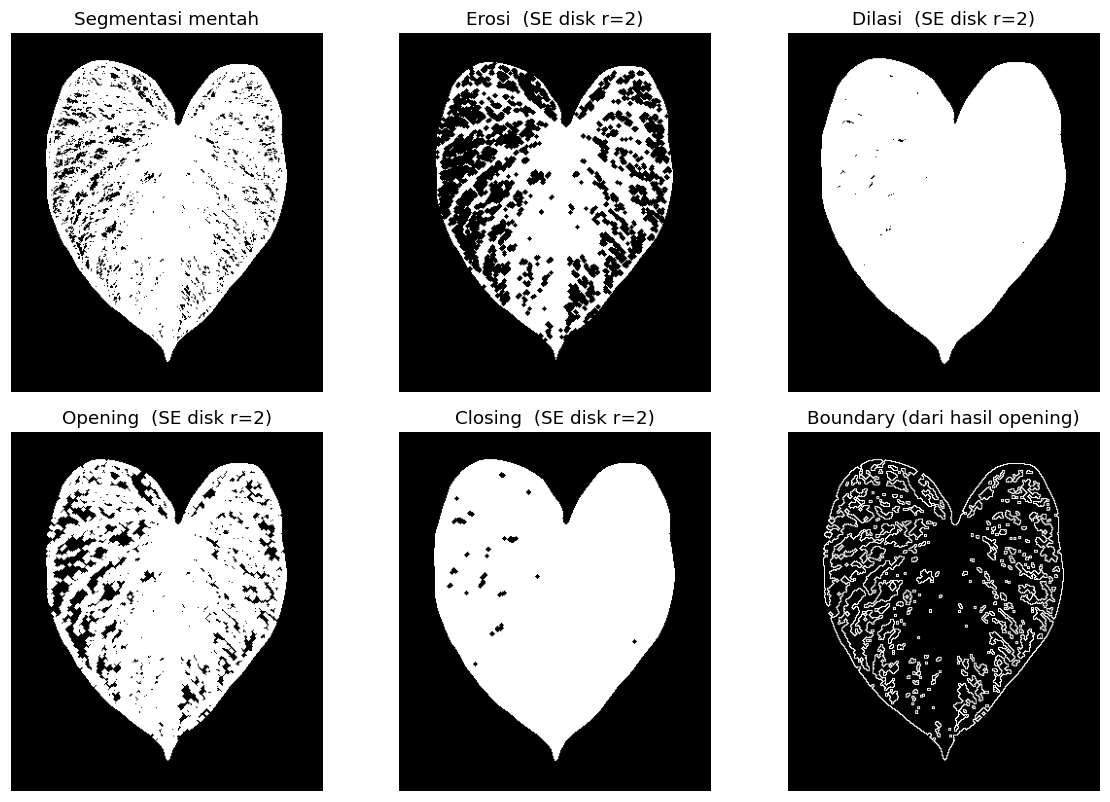

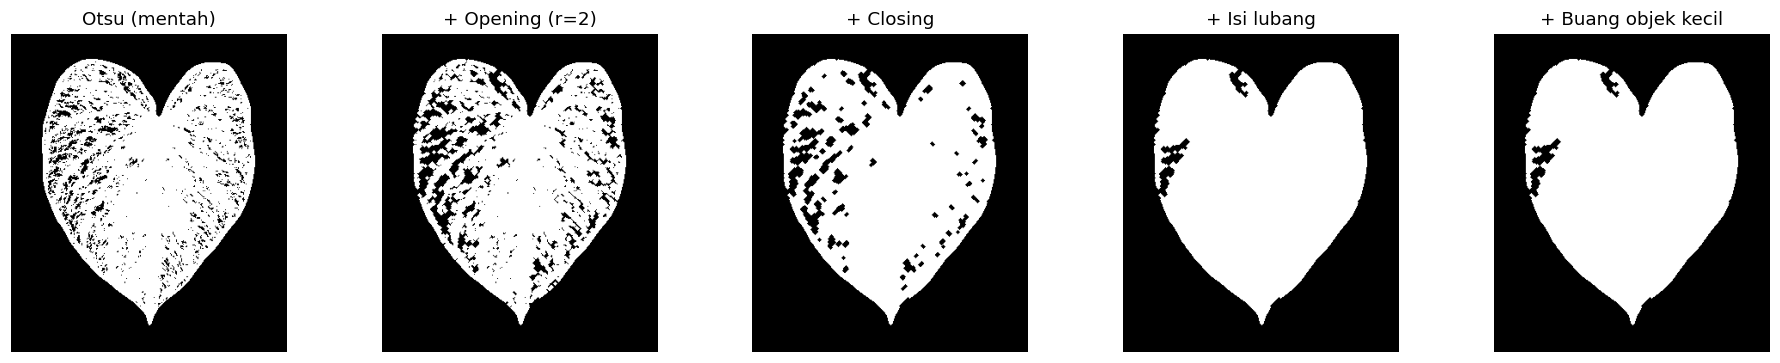

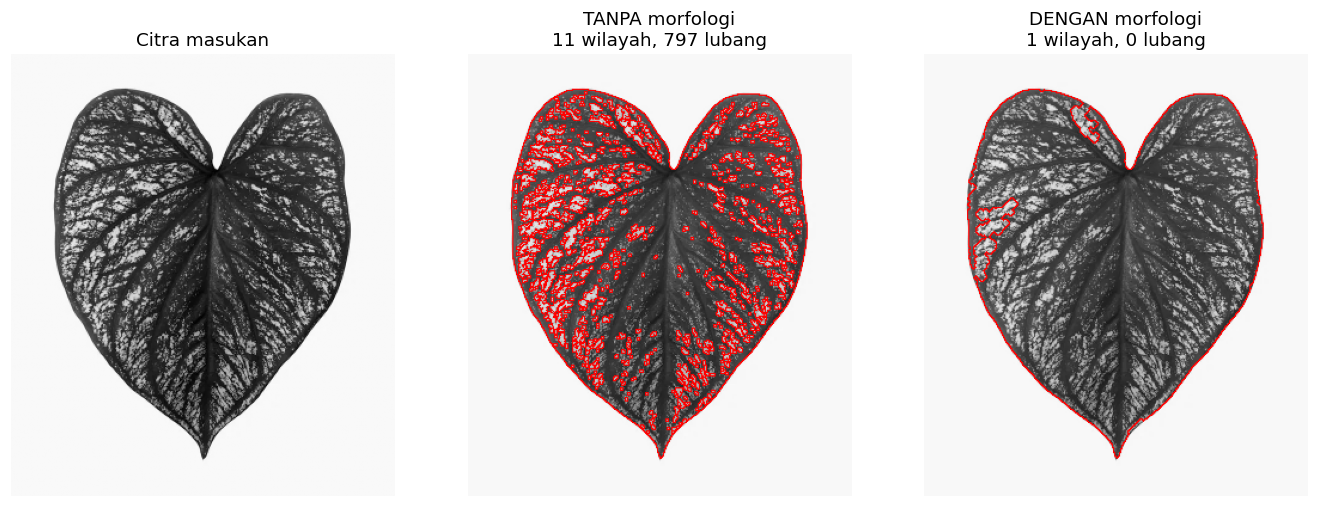

                        Tanpa morfologi  Dengan morfologi
---------------------------------------------------------
Jumlah wilayah                       11                 1
Jumlah lubang                       797                 0
Luas objek (% citra)               40.5              44.0


In [25]:
hasil_daun = proses_gambar(
    nama="Citra 1 — Daun berbintik putih",
    path="daun.jpg",
    objek_terang=False,
    se_radius=2,
    isi_lubang=True,
    min_area=200,
    tampil_operasi_dasar=True,     # tampilkan efek erosi, dilasi, opening, closing, boundary
)

## 8. Citra 2 — Butir beras di latar hitam

**Tantangan:** butir di tengah menumpuk dan saling menempel, sedangkan butir di pinggir tersebar. Celah-celah kecil di tumpukan jadi lubang.  
**Strategi:** SE kecil (`se_radius=1`) dan **tanpa** pengisian lubang, supaya bentuk butir tidak hilang.

  Citra 2 — Butir beras
Ukuran citra: (213, 370) | ground truth: tidak ada
Ambang batas Otsu = 100


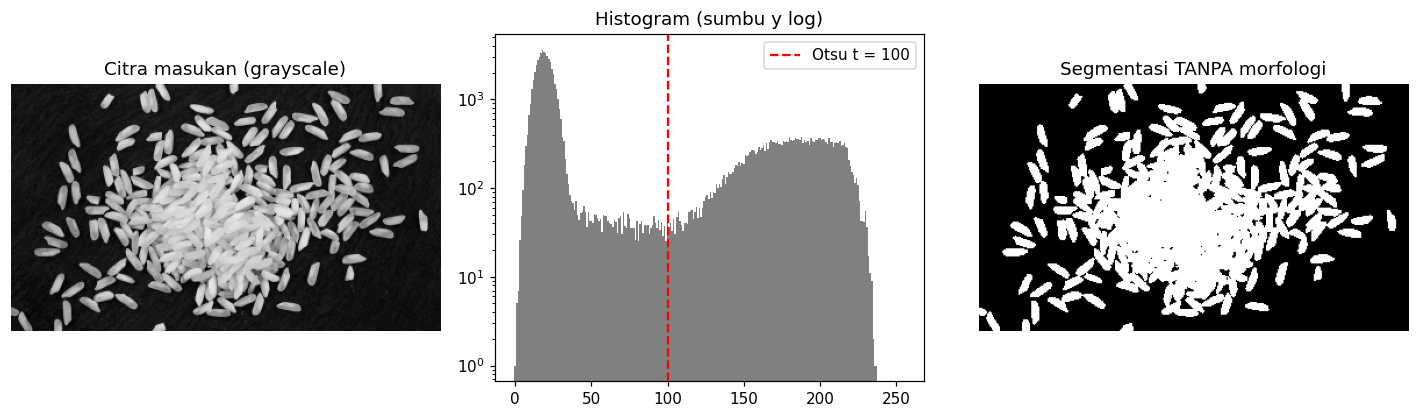

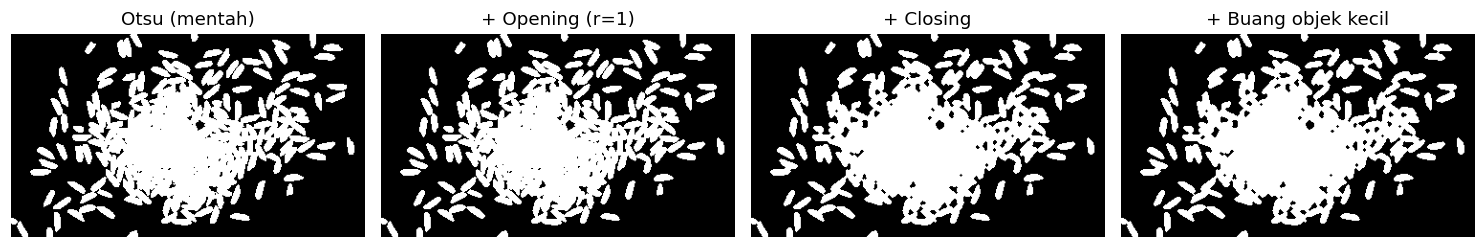

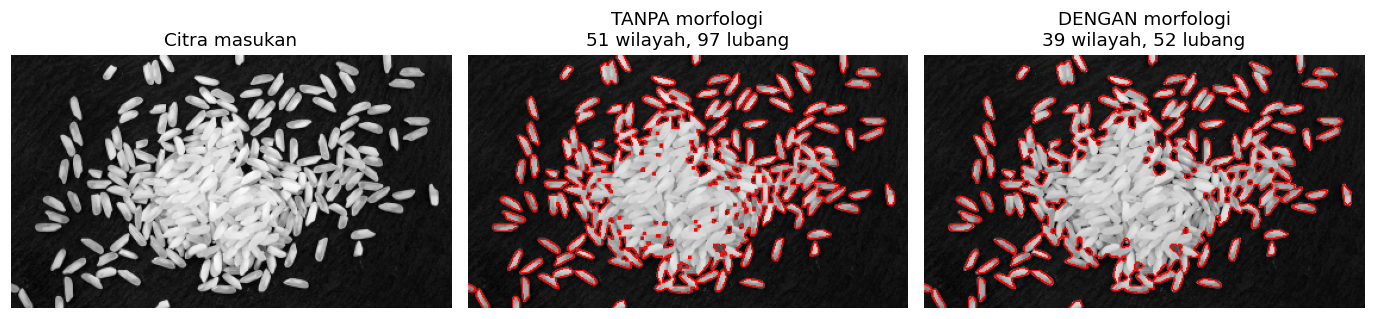

                        Tanpa morfologi  Dengan morfologi
---------------------------------------------------------
Jumlah wilayah                       51                39
Jumlah lubang                        97                52
Luas objek (% citra)               35.0              35.8


In [26]:
hasil_beras = proses_gambar(
    nama="Citra 2 — Butir beras",
    path="beras.jpg",
    objek_terang=True,
    se_radius=1,
    isi_lubang=False,
    min_area=30,
)

## 9. Citra 3 — Biji kopi di latar putih

**Tantangan:** biji kopi **lebih gelap** dari latarnya. Biji menumpuk padat di tengah dan tersebar di pinggir. Pantulan cahaya pada biji dan celah di antara biji menjadi ratusan lubang kecil di hasil segmentasi.  
**Strategi:** objek lebih gelap dari latar, jadi `objek_terang=False`. Pakai SE kecil (`se_radius=1`) dan **pengisian lubang**, karena lubangnya hanya celah dan pantulan cahaya yang kecil.

  Citra 3 — Biji kopi
Ukuran citra: (203, 306) | ground truth: tidak ada
Ambang batas Otsu = 91


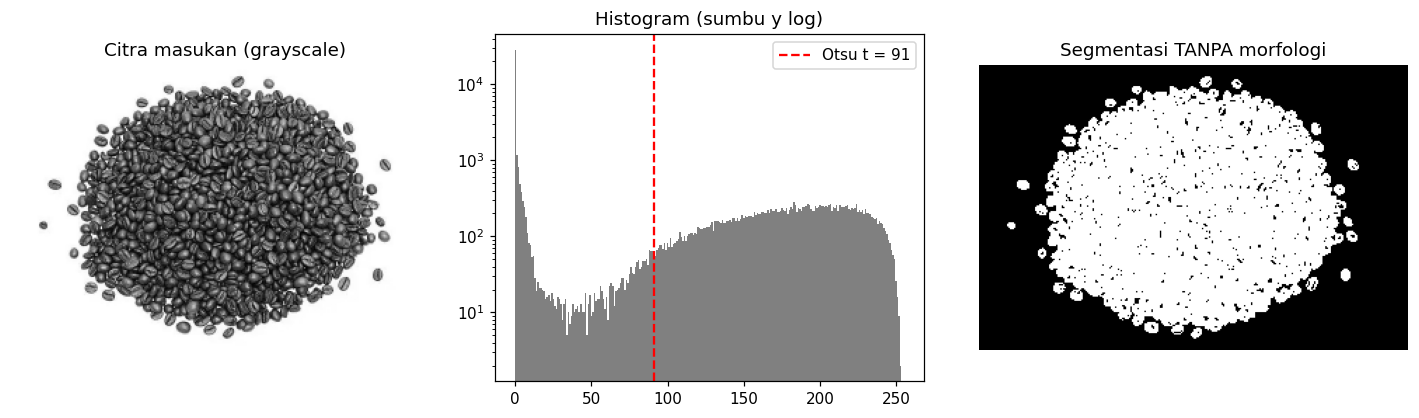

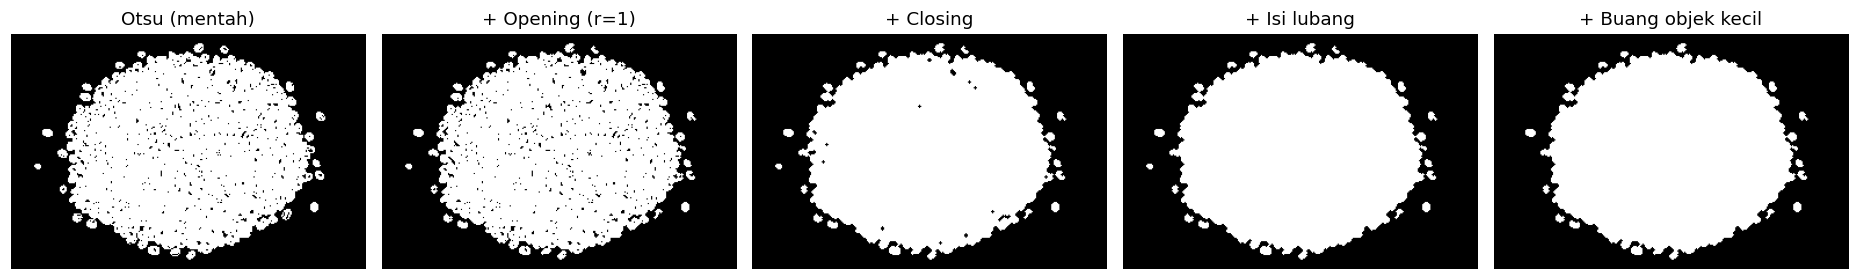

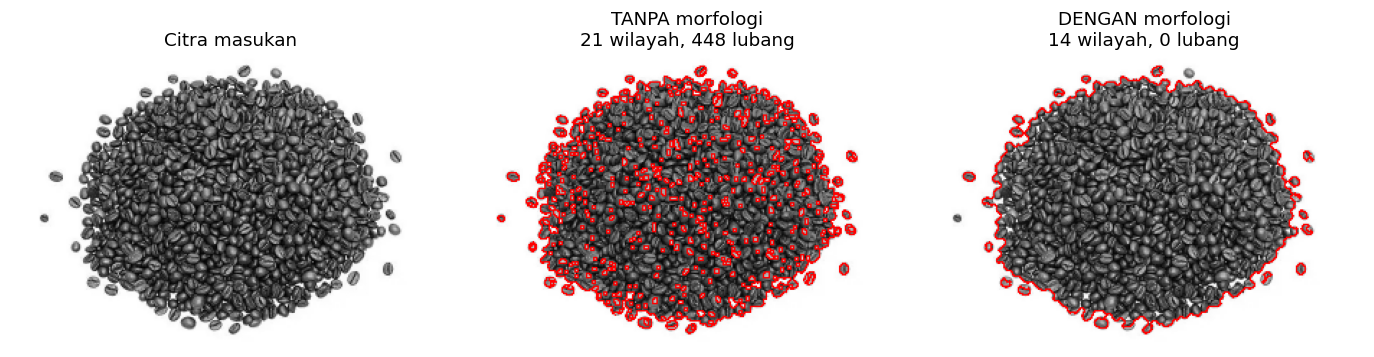

                        Tanpa morfologi  Dengan morfologi
---------------------------------------------------------
Jumlah wilayah                       21                14
Jumlah lubang                       448                 0
Luas objek (% citra)               45.1              46.5


In [27]:
try:
    hasil_3 = proses_gambar(
        nama="Citra 3 — Biji kopi",
        path="kopi.jpg",
        objek_terang=False,      # biji kopi lebih GELAP dari latar putih
        se_radius=1,
        isi_lubang=True,
        min_area=30,
    )
except FileNotFoundError:
    hasil_3 = None
    print("File 'kopi.jpg' belum ada di folder ini. Taruh gambarnya dengan nama itu, lalu jalankan ulang sel ini.")

## 10. Citra sintetis dengan noise dan ground truth

Citra ini sengaja dibuat dengan noise yang kuat dan **ground truth** yang diketahui. Fungsinya sebagai **pembuktian berangka**: karena jawaban yang benar diketahui, efek morfologi bisa diukur dengan IoU, Dice, dan sebagainya.

  Bonus — Sintetis berderau
Ukuran citra: (256, 256) | ground truth: ada
Ambang batas Otsu = 125


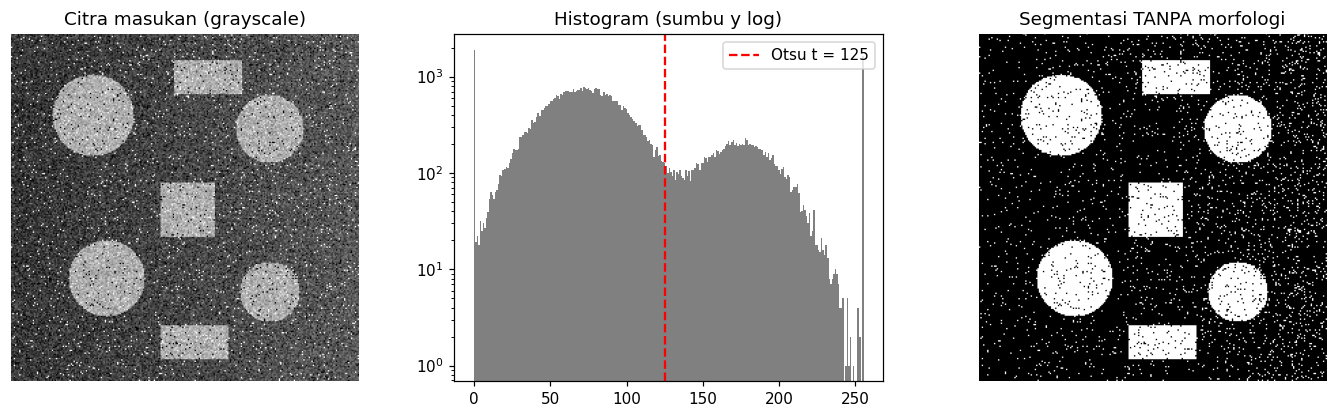

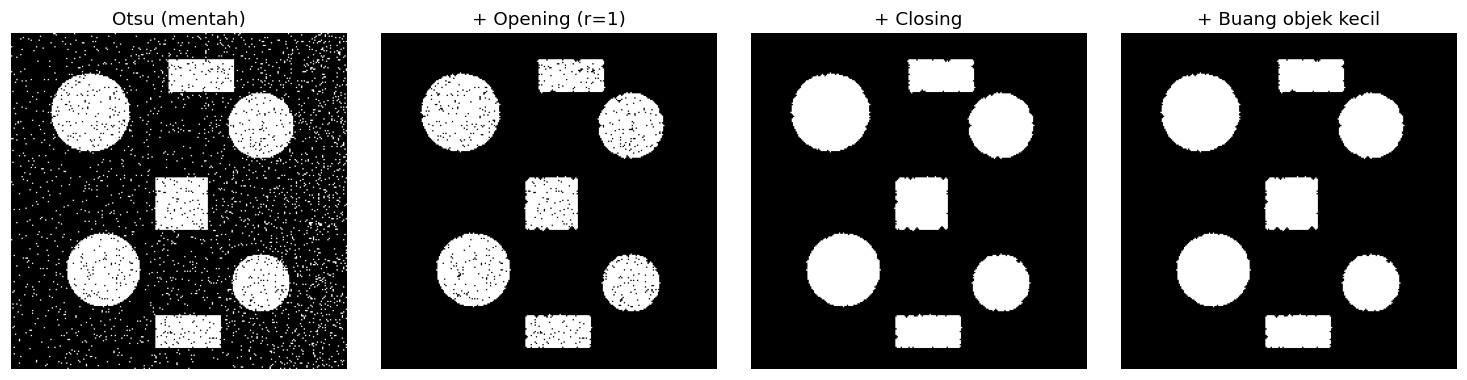

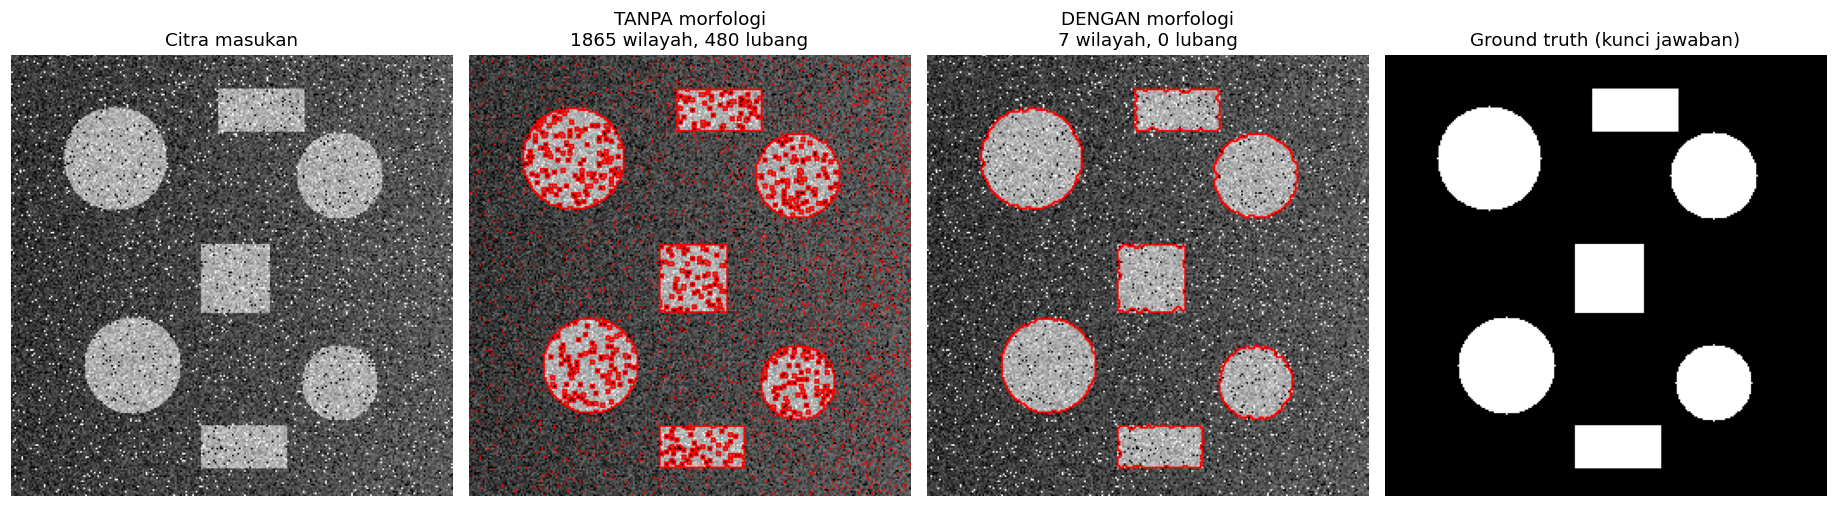

                        Tanpa morfologi  Dengan morfologi
---------------------------------------------------------
Jumlah wilayah                     1865                 7
Jumlah lubang                       480                 0
Luas objek (% citra)               22.3              19.3

Jumlah objek sebenarnya (ground truth): 7

Metrik        Tanpa morfologi  Dengan morfologi   Selisih
---------------------------------------------------------
IoU                    0.8031            0.9826   +0.1795
Dice                   0.8908            0.9912   +0.1004
Precision              0.8375            0.9985   +0.1610
Recall                 0.9513            0.9840   +0.0328
Accuracy               0.9543            0.9966   +0.0423


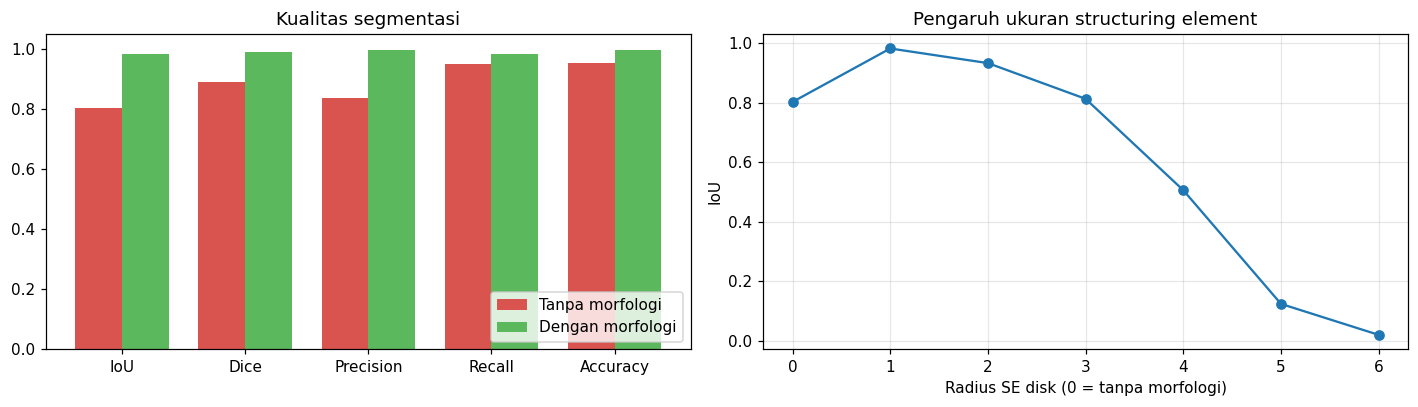

Radius SE terbaik: 1 -> IoU = 0.9826


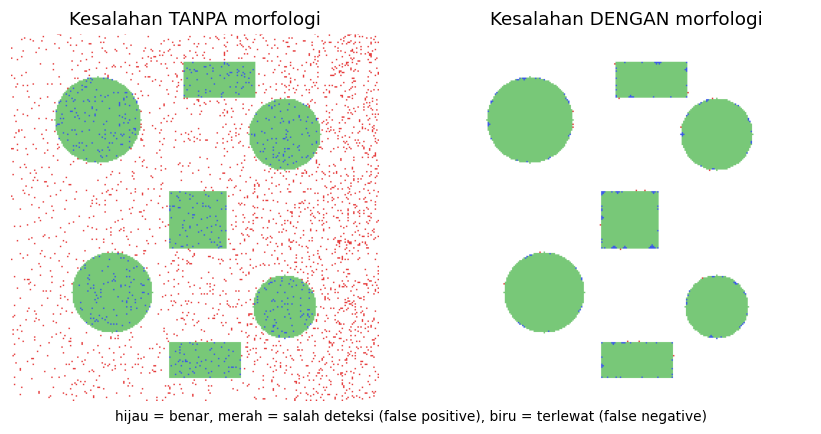

In [28]:
hasil_sintetis = proses_gambar(
    nama="Bonus — Sintetis berderau",
    path=None,                     # None = citra sintetis
    objek_terang=True,
    se_radius=1,
    isi_lubang=False,
    min_area=60,
)

## 11. Ringkasan semua citra

In [29]:
semua = [h for h in [hasil_daun, hasil_beras, hasil_3, hasil_sintetis] if h is not None]

def pasang(a, b, fmt="d"):
    return f"{a:{fmt}} -> {b:{fmt}}"

print(f"{'Citra':<34}{'Otsu t':>7}{'Wilayah':>16}{'Lubang':>16}{'Luas objek (%)':>20}")
print(f"{'':<34}{'':>7}{'tanpa -> dengan':>16}{'tanpa -> dengan':>16}{'tanpa -> dengan':>20}")
print("-"*93)
for h in semua:
    print(f"{h['nama']:<34}{h['t']:>7d}"
          f"{pasang(h['n_raw'], h['n_morph']):>16}"
          f"{pasang(h['h_raw'], h['h_morph']):>16}"
          f"{pasang(h['luas_raw'], h['luas_morph'], '.1f'):>20}")

if 'iou_raw' in hasil_sintetis:
    print(f"\nPada citra sintetis (punya ground truth): IoU naik dari {hasil_sintetis['iou_raw']:.3f} menjadi {hasil_sintetis['iou_morph']:.3f}")

Citra                              Otsu t         Wilayah          Lubang      Luas objek (%)
                                          tanpa -> dengan tanpa -> dengan     tanpa -> dengan
---------------------------------------------------------------------------------------------
Citra 1 — Daun berbintik putih         93         11 -> 1        797 -> 0        40.5 -> 44.0
Citra 2 — Butir beras                 100        51 -> 39        97 -> 52        35.0 -> 35.8
Citra 3 — Biji kopi                    91        21 -> 14        448 -> 0        45.1 -> 46.5
Bonus — Sintetis berderau             125       1865 -> 7        480 -> 0        22.3 -> 19.3

Pada citra sintetis (punya ground truth): IoU naik dari 0.803 menjadi 0.983


## 12. Pembahasan & Kesimpulan

**Tanpa morfologi** — Otsu hanya melihat nilai intensitas tiap piksel dan tidak peduli dengan posisi piksel di sekitarnya. Akibatnya hasil binernya mudah dirusak oleh noise, bayangan, atau bagian objek yang kecerahannya mirip latar:
* **Daun:** bercak putih dianggap latar, sehingga daun berlubang-lubang dan terpecah menjadi beberapa wilayah.
* **Beras:** celah-celah kecil di antara butir pada tumpukan menjadi ratusan lubang kecil.
* **Kopi:** pantulan cahaya pada biji dan celah di antara biji pada tumpukan menjadi ratusan lubang kecil.
* **Citra sintetis:** bintik putih di latar (false positive) dan lubang hitam di dalam objek (false negative) membuat ribuan wilayah kecil.

**Dengan morfologi** — setiap operasi punya peran:
* **Opening** menghapus bintik putih yang lebih kecil dari structuring element, bentuk objek besar tetap terjaga.
* **Closing** menutup lubang dan celah kecil serta menghaluskan kontur.
* **Pengisian lubang** menutup semua lubang yang terkurung di dalam objek. Sangat berguna pada daun, tetapi pada tumpukan beras justru menghilangkan bentuk butir.
* **Penghapusan wilayah kecil** (lewat komponen terhubung) membuang sisa gumpalan yang masih lolos.

**Parameter harus disesuaikan dengan citra.** Daun butuh SE lebih besar dan pengisian lubang; beras cukup SE kecil tanpa pengisian lubang agar bentuk butir terjaga; kopi cukup SE kecil dengan pengisian lubang karena lubangnya hanya celah dan pantulan cahaya yang kecil; citra sintetis hanya berisi noise piksel tunggal sehingga SE radius 1 sudah cukup. SE yang terlalu besar membulatkan sudut, menggabungkan objek yang berdekatan, dan bisa menghapus bagian objek yang tipis.

**Keterbatasan:**
* Otsu mengandaikan histogram yang punya dua puncak. Pada objek putih di latar putih (misalnya beras putih di kertas putih), Otsu gagal karena kontrasnya terlalu kecil.
* Menentukan `objek_terang` dengan benar itu penting: kalau terbalik, yang tersegmentasi justru latarnya, dan hasilnya tampak wajar karena tepi latar berimpit dengan tepi objek. Periksa luas objek dan pesan peringatan yang ditampilkan.
* Pada tumpukan beras dan biji kopi, butir yang saling menempel tetap tidak bisa dipisahkan dengan threshold dan morfologi sederhana; untuk itu dibutuhkan metode lain seperti watershed.
* Closing dan pengisian lubang bisa menggabungkan objek yang berdekatan, sehingga jumlah wilayah yang turun tidak selalu berarti hasilnya lebih akurat.

**Kesimpulan:** thresholding saja cepat dan sederhana, tetapi mudah terganggu noise dan variasi kecerahan. Operasi morfologi (opening, closing, pengisian lubang) adalah langkah pasca-pengolahan yang murah dan efektif untuk memperbaiki hasil segmentasi, asalkan ukuran structuring element dan jenis operasinya dipilih sesuai karakter citra.